> **Course source:** [langgraph/agent.ipynb](https://huggingface.co/agents-course/notebooks/blob/cecf8edffb02101c90634b84076bd93b1a20c713/unit2/langgraph/agent.ipynb).
> **Compatibility:** The original graph and both queries use Groq native tools. The original course image is downloaded and passed to the multimodal Qwen model. Each run checks for an actual successful tool response.

# Agent

In this notebook, **we're going to build a simple agent using using LangGraph**.

This notebook is part of the <a href="https://www.hf.co/learn/agents-course">Hugging Face Agents Course</a>, a free course from beginner to expert, where you learn to build Agents.

![Agents course share](https://huggingface.co/datasets/agents-course/course-images/resolve/main/en/communication/share.png)

As seen in the Unit 1, an agent needs 3 steps as introduced in the ReAct architecture :
[ReAct](https://react-lm.github.io/), a general agent architecture.

* `act` - let the model call specific tools
* `observe` - pass the tool output back to the model
* `reason` - let the model reason about the tool output to decide what to do next (e.g., call another tool or just respond directly)


![Agent](https://huggingface.co/datasets/agents-course/course-images/resolve/main/en/unit2/LangGraph/Agent.png)

In [1]:
COURSE_PACKAGES = ['langgraph==1.2.22', 'langchain-openai==1.8.0']

import os
import subprocess
import sys

if not os.environ.get("HF_COURSE_BATCH"):
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                    "--disable-pip-version-check", *COURSE_PACKAGES], check=True, timeout=600)

In [2]:
import json
import os
from functools import lru_cache

import httpx
from openai import OpenAI

GROQ_BASE = "https://api.groq.com/openai/v1"
QWEN = "qwen/qwen3.8-27b"
GPT_OSS = ("openai/gpt-oss-20b", "openai/gpt-oss-120b")


def optional_secret(name):
    """Read a notebook-authorized secret without printing it."""
    if os.getenv(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except ImportError:
        return None
    except Exception as exc:
        if type(exc).__name__ in {"SecretNotFoundError", "NotebookAccessError"}:
            return None
        raise


@lru_cache(maxsize=1)
def groq_account():
    key = optional_secret("GROQ_API_KEY")
    if not key:
        raise RuntimeError("Enable notebook access to the GROQ_API_KEY secret in Colab.")
    with OpenAI(api_key=key, base_url=GROQ_BASE, timeout=20, max_retries=0) as client:
        return key, frozenset(model.id for model in client.models.list().data)


class ModelRouting:
    def __init__(self, models, mode):
        self.models = list(models)
        self.mode = mode

    def requests(self, request):
        if request.method != "POST" or not request.url.path.endswith("/chat/completions"):
            yield None, request
            return
        body = json.loads(request.content)
        headers = {key: val for key, val in request.headers.items()
                   if key not in {"content-length", "transfer-encoding"}}
        if self.mode == "code" and body.get("tools"):
            raise ValueError("CodeAgent uses Python actions. Its API request must have no native tools.")
        for model_id in tuple(self.models):
            payload = {**body, "model": model_id}
            max_tokens = payload.pop("max_tokens", None)
            if max_tokens and "max_completion_tokens" not in payload:
                payload["max_completion_tokens"] = max_tokens
            if model_id in GPT_OSS:
                payload.pop("parallel_tool_calls", None)
                payload.pop("stop", None)
                payload["reasoning_effort"] = "low"
            elif model_id == QWEN:
                payload["reasoning_effort"] = "none"
            yield model_id, httpx.Request(
                request.method, request.url, json=payload, headers=headers,
                extensions=request.extensions,
            )

    def accept(self, model_id, status, attempt):
        if model_id is None:
            return True
        if status in {429, 503} and attempt < len(self.models):
            return False
        if 200 <= status < 300 and model_id != self.models[0]:
            self.models.remove(model_id)
            self.models.insert(0, model_id)
            print(f"Groq fallback model: {model_id}", flush=True)
        return True


class CourseTransport(httpx.HTTPTransport):
    def __init__(self, routing):
        super().__init__(retries=0)
        self.routing = routing

    def handle_request(self, request):
        for attempt, (model_id, candidate) in enumerate(self.routing.requests(request), 1):
            response = super().handle_request(candidate)
            if self.routing.accept(model_id, response.status_code, attempt):
                return response
            response.close()


class AsyncCourseTransport(httpx.AsyncHTTPTransport):
    def __init__(self, routing):
        super().__init__(retries=0)
        self.routing = routing

    async def handle_async_request(self, request):
        for attempt, (model_id, candidate) in enumerate(self.routing.requests(request), 1):
            response = await super().handle_async_request(candidate)
            if self.routing.accept(model_id, response.status_code, attempt):
                return response
            await response.aclose()


@lru_cache(maxsize=3)
def groq_route(mode):
    key, available = groq_account()
    candidates = {
        "text": (QWEN, *GPT_OSS),
        "vision": (QWEN,),
        "code": (QWEN, *GPT_OSS),
    }[mode]
    models = [model_id for model_id in candidates if model_id in available]
    if not models:
        raise RuntimeError(f"None of the Groq {mode} models are enabled for this project: {candidates}")
    print(f"Groq {mode} candidates, in order: {', '.join(models)}", flush=True)
    return key, ModelRouting(models, mode)


@lru_cache(maxsize=1)
def make_groq_llm():
    from llama_index.llms.openai_like import OpenAILike
    key, routing = groq_route("text")
    return OpenAILike(
        model=routing.models[0], api_base=GROQ_BASE, api_key=key,
        is_chat_model=True, is_function_calling_model=True, context_window=32768,
        max_tokens=1024, temperature=0.1, timeout=30, max_retries=0,
        http_client=httpx.Client(transport=CourseTransport(routing), timeout=30),
        async_http_client=httpx.AsyncClient(transport=AsyncCourseTransport(routing), timeout=30),
    )


@lru_cache(maxsize=2)
def make_chat_model(mode="text"):
    from langchain_openai import ChatOpenAI
    key, routing = groq_route(mode)
    return ChatOpenAI(
        model=routing.models[0], base_url=GROQ_BASE, api_key=key,
        temperature=0.1, max_tokens=1024, timeout=30, max_retries=0,
        http_client=httpx.Client(transport=CourseTransport(routing), timeout=30),
        http_async_client=httpx.AsyncClient(transport=AsyncCourseTransport(routing), timeout=30),
    )


@lru_cache(maxsize=1)
def make_code_model():
    from smolagents import OpenAIModel
    key, routing = groq_route("code")
    return OpenAIModel(
        model_id=routing.models[0], api_base=GROQ_BASE, api_key=key,
        max_tokens=1800, temperature=0.1, retry=False,
        client_kwargs={
            "http_client": httpx.Client(transport=CourseTransport(routing), timeout=30),
            "timeout": 30, "max_retries": 0,
        },
    )

def display_course_graph(graph):
    import json
    import shutil
    from IPython.display import Image, display
    mermaid = graph.draw_mermaid()
    print(mermaid)
    if not shutil.which("dot"):
        print("Graphviz is unavailable. The compiled graph is listed above in Mermaid.")
        return
    dot = ["digraph course {", "rankdir=TB;", 'node [shape=box, style=rounded];']
    for node_id in graph.nodes:
        dot.append(f"{json.dumps(node_id)};")
    for edge in graph.edges:
        label = json.dumps(str(edge.data or ""))
        style = "dashed" if edge.conditional else "solid"
        dot.append(f"{json.dumps(edge.source)} -> {json.dumps(edge.target)} [label={label},style={style}];")
    dot.append("}")
    png = subprocess.run(["dot", "-Tpng"], input="\n".join(dot).encode(),
                         capture_output=True, check=True, timeout=10).stdout
    display(Image(png))

In [3]:
import base64
from langchain_core.messages import HumanMessage

def extract_text(img_path: str) -> str:
    """Use OCR on the course image at img_path and return the text."""
    if img_path != "Batman_training_and_meals.png":
        raise ValueError("This exercise only reads the downloaded course image.")
    with open(img_path, "rb") as image_file:
        encoded = base64.b64encode(image_file.read()).decode("ascii")
    prompt = HumanMessage(content=[
        {"type": "text", "text": "Extract all the text from this image. Return only the extracted text, no explanations."},
        {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{encoded}"}},
    ])
    from openai import RateLimitError
    from shutil import which
    try:
        result = make_chat_model("vision").invoke([prompt]).content
    except RateLimitError:
        if not which("tesseract"):
            raise
        print("Vision model quota exhausted. Using local Tesseract on the original image.")
        result = subprocess.run(
            ["tesseract", img_path, "stdout", "--psm", "3"],
            capture_output=True, text=True, check=True, timeout=25,
        ).stdout
    if not isinstance(result, str) or not result.strip():
        raise RuntimeError("The vision model returned no OCR text.")
    return result.strip()

def divide(a: int, b: int) -> float:
    """Divide a and b."""
    return a / b

tools = [divide, extract_text]

@lru_cache(maxsize=1)
def chat_with_tools():
    return make_chat_model().bind_tools(tools, parallel_tool_calls=False)

Let's create our LLM and prompt it with the overall desired agent behavior.

In [4]:
from typing import TypedDict, Annotated, Optional
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages


class AgentState(TypedDict):
    # The input document
    input_file: Optional[str]  # Contains file path, type (PNG)
    messages: Annotated[list[AnyMessage], add_messages]

In [5]:
from langchain_core.messages import SystemMessage, ToolMessage

def assistant(state: AgentState):
    image = state["input_file"]
    prompt = SystemMessage(content=(
        "You are a helpful assistant that can analyse images and perform arithmetic. "
        "For division call divide. For any question about the note call extract_text "
        f"with the available file path ({image}). Use the tool result to answer. "
        "After a successful tool response, answer without calling the tool again. For a dinner-only request, list only items from the Dinner section."
    ))
    return {"messages": [chat_with_tools().invoke([prompt, *state["messages"]])]}

def verify_tool(result, name):
    assert any(isinstance(m, ToolMessage) and m.name == name
               and m.status == "success" and m.content for m in result["messages"]), name
    assert result["messages"][-1].content, "Missing final answer"

We define a `tools` node with our list of tools.

The `assistant` node is just our model with bound tools.

We create a graph with `assistant` and `tools` nodes.

We add `tools_condition` edge, which routes to `End` or to `tools` based on  whether the `assistant` calls a tool.

Now, we add one new step:

We connect the `tools` node *back* to the `assistant`, forming a loop.

* After the `assistant` node executes, `tools_condition` checks if the model's output is a tool call.
* If it is a tool call, the flow is directed to the `tools` node.
* The `tools` node connects back to `assistant`.
* This loop continues as long as the model decides to call tools.
* If the model response is not a tool call, the flow is directed to END, terminating the process.

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	assistant(assistant)
	tools(tools<hr/><small><em>__tools = divide, extract_text</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> assistant;
	assistant -.-> __end__;
	assistant -.-> tools;
	tools --> assistant;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



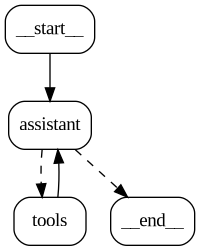

In [6]:
from langgraph.graph import START, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display

# Graph
builder = StateGraph(AgentState)

# Define nodes: these do the work
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools, handle_tool_errors=False))

# Define edges: these determine how the control flow moves
builder.add_edge(START, "assistant")
builder.add_conditional_edges(
    "assistant",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools", "assistant")
react_graph = builder.compile()

# Show
display_course_graph(react_graph.get_graph(xray=True))

In [7]:
messages = [HumanMessage(content="Divide 6790 by 5")]

division_result = react_graph.invoke({"messages": messages, "input_file": None}, {"recursion_limit": 8})
verify_tool(division_result, "divide")

Groq text candidates, in order: qwen/qwen3.8-27b, openai/gpt-oss-20b, openai/gpt-oss-120b
Groq fallback model: openai/gpt-oss-20b


langchain-openai injected a custom httpx transport to apply `http_socket_options`, which disables httpx's proxy auto-detection (system proxy configuration detected). Set `LANGCHAIN_OPENAI_TCP_KEEPALIVE=0` or pass `http_socket_options=()` to restore default proxy behavior, or supply `openai_proxy` / your own `http_client` / `http_async_client` to take full control.


In [8]:
for m in division_result['messages']:
    m.pretty_print()

================================ Human Message =================================

Divide 6790 by 5
================================== Ai Message ==================================
Tool Calls:
  divide (fc_aaaabc17-0f9f-4b59-a140-949fac4f6efc)
 Call ID: fc_aaaabc17-0f9f-4b59-a140-949fac4f6efc
  Args:
    a: 6790
    b: 5
================================= Tool Message =================================
Name: divide

1358.0
================================== Ai Message ==================================

1358.0


## Training program
MR Wayne left a note with his training program for the week. I came up with a recipe for dinner left in a note.

you can find the document [HERE](https://huggingface.co/datasets/agents-course/course-images/blob/main/en/unit2/LangGraph/Batman_training_and_meals.png), so download it and upload it in the local folder.

![Training](https://huggingface.co/datasets/agents-course/course-images/resolve/main/en/unit2/LangGraph/Batman_training_and_meals.png)

In [9]:
import requests
from pathlib import Path

image_path = Path("Batman_training_and_meals.png")
if not image_path.is_file():
    image_url = "https://huggingface.co/datasets/agents-course/course-images/resolve/main/en/unit2/LangGraph/Batman_training_and_meals.png"
    response = requests.get(image_url, timeout=30)
    response.raise_for_status()
    if not response.content.startswith(b"\x89PNG\r\n\x1a\n"):
        raise ValueError("Expected the course PNG.")
    image_path.write_bytes(response.content)
print(image_path, image_path.stat().st_size, "bytes")

Batman_training_and_meals.png 843388 bytes


In [10]:
messages = [HumanMessage(content="According the note provided by MR wayne in the provided images. What's the list of items I should buy for the dinner menu ?")]

ocr_result = react_graph.invoke({"messages": messages, "input_file": str(image_path)}, {"recursion_limit": 8})
verify_tool(ocr_result, "extract_text")

Groq vision candidates, in order: qwen/qwen3.8-27b
Vision model quota exhausted. Using local Tesseract on the original image.


In [11]:
for m in ocr_result['messages']:
    m.pretty_print()

================================ Human Message =================================

According the note provided by MR wayne in the provided images. What's the list of items I should buy for the dinner menu ?
================================== Ai Message ==================================
Tool Calls:
  extract_text (fc_c33982df-d921-43fc-996f-c4ef47e252a4)
 Call ID: fc_c33982df-d921-43fc-996f-c4ef47e252a4
  Args:
    img_path: Batman_training_and_meals.png
================================= Tool Message =================================
Name: extract_text

TRAINING SCHEDULE
For the week of 2/20-2/26

‘SUNDAY 2/20

MORNING
30 minute jog
30 minute meditation
EVENING
clean and jerk ifts - 3 reps/8 sets. 262 Ibs.
5 sets metabolic conditioning:
Ye mile run
21 kettlebell swings
12 pull-ups
30 minutes flexibility
30 minutes sparring

MONDAY 2/21

MORNING
30 minute jog
30 minutes traditional kata (focus on Japanese forms)

EVENING
5 sets 20 foot rope climb
30 minutes gymnastic rings (work on muscl